# Passau MedCo · Attrition Prediction and XAI

Train and evaluate attrition models using the employee dataset.

## 1. Imports

Import the tools for preprocessing, training, evaluation, and plotting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

## 2. Load data

Read the employee CSV used for model training.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)

## 3. Model training and predictions

Tune logistic regression and random forest, then compare each against its original configuration.

### Prepare features and split the data

Validate employee IDs and target labels, then keep the original stratified 80/20 split.

In [3]:
random_seed = 42
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].notna().all() and employees["EmployeeNumber"].is_unique
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

constant_columns = employees.columns[employees.nunique(dropna=False).eq(1)].tolist()
X = employees.drop(columns=["EmployeeNumber", "Attrition", *constant_columns])
y = employees["Attrition"].eq("Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=random_seed
)

display(pd.DataFrame({
    "Employees": [len(y_train), len(y_test)],
    "Departures": [y_train.sum(), y_test.sum()],
}, index=["Train", "Test"]))

,Employees,Departures
Train,1176,190
Test,294,47


### Set up the search

Search regularization, class weights, and skewed-feature transforms for logistic regression, and tree complexity, feature sampling, and class weights for random forest.

In [4]:
categorical_features = X_train.select_dtypes(include="str").columns.tolist()
model_numeric_features = X_train.select_dtypes(include="number").columns.tolist()
skewed_features = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
other_numeric_features = X_train[model_numeric_features].columns.difference(skewed_features).tolist()

original_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), model_numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
logistic_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), other_numeric_features),
    ("skewed", StandardScaler(), skewed_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
forest_preprocessing = ColumnTransformer([
    ("numeric", "passthrough", model_numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

original_models = {
    "Logistic regression": make_pipeline(original_preprocessing, LogisticRegression(C=1.0, max_iter=1000)),
    "Random forest": make_pipeline(
        original_preprocessing,
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=random_seed),
    ),
}
inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=random_seed)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)
search_options = {"cv": inner_cv, "scoring": "average_precision", "n_jobs": 4, "error_score": "raise"}

searches = {
    "Logistic regression": GridSearchCV(
        make_pipeline(logistic_preprocessing, LogisticRegression(max_iter=1000)),
        {
            "logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0],
            "logisticregression__class_weight": [None, "balanced"],
            "columntransformer__skewed": [StandardScaler(), PowerTransformer()],
        },
        **search_options,
    ),
    "Random forest": GridSearchCV(
        make_pipeline(forest_preprocessing, RandomForestClassifier(n_estimators=150, random_state=random_seed)),
        {
            "randomforestclassifier__max_depth": [8, None],
            "randomforestclassifier__min_samples_leaf": [1, 3, 8],
            "randomforestclassifier__max_features": ["sqrt", 0.6],
            "randomforestclassifier__class_weight": [None, "balanced"],
        },
        **search_options,
    ),
}

### Validate tuning on training folds

Use nested cross-validation to compare ranking quality and check the F2 threshold on unseen folds. Select the classifier by mean outer-fold AP.

In [5]:
def choose_thresholds(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    precision, recall = precision[:-1], recall[:-1]
    selected_thresholds = {}

    for beta in [1, 2]:
        beta_squared = beta ** 2
        denominator = (beta_squared * precision + recall).clip(min=1e-12)
        f_beta = (1 + beta_squared) * precision * recall / denominator
        selected_thresholds[f"F{beta}"] = float(thresholds[f_beta.argmax()])

    return selected_thresholds
fold_results = []
for fold_number, (fit_indices, validation_indices) in enumerate(outer_cv.split(X_train, y_train), start=1):
    X_fit, X_validation = X_train.iloc[fit_indices], X_train.iloc[validation_indices]
    y_fit, y_validation = y_train.iloc[fit_indices], y_train.iloc[validation_indices]

    for model_name, search in searches.items():
        original = clone(original_models[model_name]).fit(X_fit, y_fit)
        tuned = clone(search).fit(X_fit, y_fit)
        validation_scores = tuned.predict_proba(X_validation)[:, 1]
        fold_training_scores = cross_val_predict(
            tuned.best_estimator_, X_fit, y_fit, cv=inner_cv, method="predict_proba"
        )[:, 1]
        f2_threshold = choose_thresholds(y_fit, fold_training_scores)["F2"]
        validation_predictions = validation_scores >= f2_threshold

        fold_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Original AP": average_precision_score(y_validation, original.predict_proba(X_validation)[:, 1]),
            "Tuned AP": average_precision_score(y_validation, validation_scores),
            "F2 precision": precision_score(y_validation, validation_predictions, zero_division=0),
            "F2 recall": recall_score(y_validation, validation_predictions),
        })

cv_results = (
    pd.DataFrame(fold_results)
    .groupby("Model")
    .agg(
        original_ap=("Original AP", "mean"),
        tuned_ap=("Tuned AP", "mean"),
        tuned_ap_sd=("Tuned AP", "std"),
        tuned_f2_precision=("F2 precision", "mean"),
        tuned_f2_recall=("F2 recall", "mean"),
    )
    .sort_values("tuned_ap", ascending=False)
)
display(cv_results.round(3))
selected_name = cv_results.index[0]
print(f"Selected model: {selected_name}")

,original_ap,tuned_ap,tuned_ap_sd,tuned_f2_precision,tuned_f2_recall
Model,,,,,
Logistic regression,0.651,0.675,0.041,0.393,0.732
Random forest,0.571,0.566,0.081,0.352,0.768


Selected model: Logistic regression


### Set decision thresholds from training data

Compare an F1 threshold with an F2 threshold, which gives recall more weight. Use out-of-fold training scores for both thresholds.

In [6]:
tuned_models = {}
model_thresholds = {}
original_thresholds = {}

for model_name, search in searches.items():
    search.fit(X_train, y_train)
    tuned_models[model_name] = search.best_estimator_
    original_training_scores = cross_val_predict(
        original_models[model_name], X_train, y_train, cv=outer_cv, method="predict_proba"
    )[:, 1]
    tuned_training_scores = cross_val_predict(
        search.best_estimator_, X_train, y_train, cv=outer_cv, method="predict_proba"
    )[:, 1]
    original_thresholds[model_name] = choose_thresholds(y_train, original_training_scores)
    model_thresholds[model_name] = choose_thresholds(y_train, tuned_training_scores)
    print(f"{model_name}: {search.best_params_}")

display(pd.DataFrame(model_thresholds).T.round(3))
selected_model = tuned_models[selected_name]
decision_threshold = model_thresholds[selected_name]["F1"]

Logistic regression: {'columntransformer__skewed': PowerTransformer(), 'logisticregression__C': 0.1, 'logisticregression__class_weight': None}


Random forest: {'randomforestclassifier__class_weight': None, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 3}


,F1,F2
Logistic regression,0.342,0.201
Random forest,0.266,0.158


### Compare results on the original test split

Show ranking quality, recall, precision, and error counts for the original F1, tuned F1, and tuned F2 thresholds.

In [7]:
def summarize_predictions(labels, scores, predictions):
    return {
        "AP": average_precision_score(labels, scores),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions),
        "F1": f1_score(labels, predictions),
        "Accuracy": accuracy_score(labels, predictions),
        "Detected": int((predictions & labels.eq(1)).sum()),
        "False alarms": int((predictions & labels.eq(0)).sum()),
    }

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_scores = baseline.predict_proba(X_test)[:, 1]
test_results = {
    ("Majority baseline", "Always stayed"): summarize_predictions(
        y_test, baseline_scores, baseline.predict(X_test).astype(bool)
    )
}
for model_name, tuned in tuned_models.items():
    original = original_models[model_name].fit(X_train, y_train)
    original_scores = original.predict_proba(X_test)[:, 1]
    tuned_scores = tuned.predict_proba(X_test)[:, 1]

    test_results[(model_name, "Original F1")] = summarize_predictions(
        y_test, original_scores, original_scores >= original_thresholds[model_name]["F1"]
    )
    for threshold_name, threshold in model_thresholds[model_name].items():
        test_results[(model_name, f"Tuned {threshold_name}")] = summarize_predictions(
            y_test, tuned_scores, tuned_scores >= threshold
        )

test_metrics = pd.DataFrame.from_dict(test_results, orient="index")
test_metrics.index.names = ["Model", "Threshold"]
display(test_metrics.round(3))

test_scores = selected_model.predict_proba(X_test)[:, 1]
test_predictions = test_scores >= decision_threshold

AP  Precision  Recall     F1  Accuracy  \
Model               Threshold                                                  
Majority baseline   Always stayed  0.160      0.000   0.000  0.000     0.840   
Logistic regression Original F1    0.584      0.553   0.447  0.494     0.854   
                    Tuned F1       0.616      0.600   0.511  0.552     0.867   
                    Tuned F2       0.616      0.419   0.660  0.512     0.799   
Random forest       Original F1    0.453      0.429   0.574  0.491     0.810   
                    Tuned F1       0.459      0.426   0.489  0.455     0.813   
                    Tuned F2       0.459      0.336   0.766  0.468     0.721   

                                   Detected  False alarms  
Model               Threshold                              
Majority baseline   Always stayed         0             0  
Logistic regression Original F1          21            17  
                    Tuned F1             24            16  
                    Tuned F2             31            43  
Random forest       Original F1          27            36  
                    Tuned F1             23            31  
                    Tuned F2             36            71

### Compare prediction errors

Show the selected model’s test confusion matrices for the balanced and recall-focused thresholds.

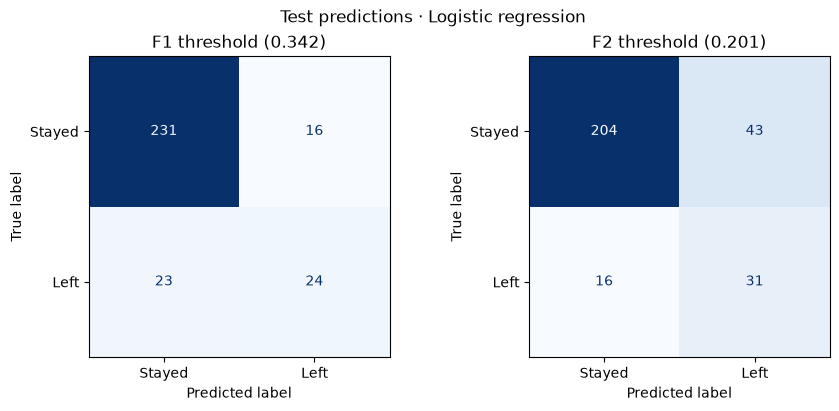

In [8]:
%matplotlib inline

fig, axes = plt.subplots(1, 2, figsize=(8.8, 4), layout="constrained")
for ax, (threshold_name, threshold) in zip(axes, model_thresholds[selected_name].items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_scores >= threshold, labels=[0, 1], display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{threshold_name} threshold ({threshold:.3f})")
fig.suptitle(f"Test predictions · {selected_name}")
plt.show()

### Model takeaway

- **Logistic regression** improved in nested CV (AP 0.651 → 0.675). The selected configuration used `C=0.1` and a power transform for three skewed features.
- **Random forest** did not improve in nested CV (AP 0.571 → 0.566). At F2 it caught more departures but generated more false alarms.
- **Test comparison:** The tuned logistic model caught 24 of 47 departures at F1 with 16 false alarms. At F2 it caught 31 of 47 with 43 false alarms. This is the same test split used in the original run.

## 4. Model explanations

Planned next step: explain three predictions with LIME and add a global explanation of the selected model.